# Predicting molecular solubility (ESOL): GCN with vs without graph structure
Each molecule, given as a SMILES string, is mapped to one number: its measured aqueous solubility $\log S$ (mol/L). The molecule is turned into a graph (atoms = nodes, bonds = edges). Case 1 uses the bonds; Case 2 is the same network with the bonds removed, to show how much the graph structure contributes.

| Case | Model |
|---|---|
| **Case 1** | GCN (4 layers, hidden width 128) |
| **Case 2** | Same network, no edges (each atom processed independently) |

In [1]:
import numpy as np
import torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt
from torch_geometric.loader import DataLoader
from torch_geometric.nn import GCNConv, global_mean_pool
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

C:\Users\keith\PycharmProjects\.venv\shared_env\Lib\site-packages\torch\jit\_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


### 1. Set up
Builds the molecular graphs and loads the datasets. Configuration and methods are found in helper scripts

Data: ex3_data_processing
- Loads the pre-split ESOL files (train / val / test, split by Bemis-Murcko scaffold, so test molecules contain unseen ring systems)
- Standardises the target $\log S$ with training-set statistics
- Returns a dictionary of datasets; each molecule carries its graph (atom features and bonds) and its standardised target

Graph: ex3_graph_helper
- Converts a SMILES string to a graph with `from_smiles` (PyTorch Geometric / RDKit) and one-hot encodes the 9 atom features (177 dims per atom)
- Visualises a molecule and its graph

In [2]:
# Get data
from ex2_data_processing import get_molecules
sets = get_molecules()

y_all = np.concatenate([s.y_raw for s in sets.values()])
print("train", len(sets["train"]), " val", len(sets["val"]), " test", len(sets["test"]), "molecules")
print(f"log S range: {y_all.min():.2f} to {y_all.max():.2f}, mean {y_all.mean():.2f}, std {y_all.std():.2f}")

train 902  val 113  test 113 molecules
log S range: -11.60 to 1.58, mean -3.05, std 2.10


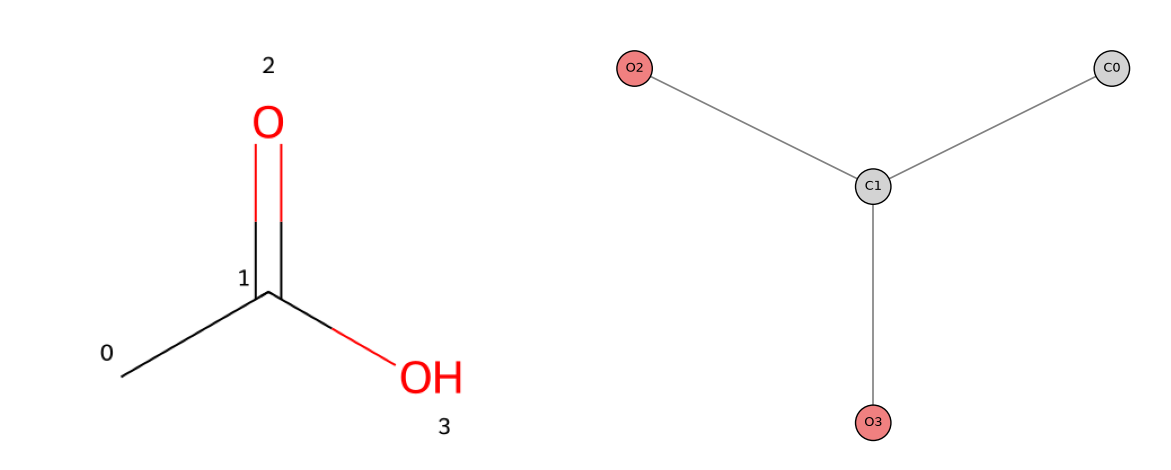

Data(x=[11, 177], edge_index=[2, 20], y=[1])
x: (11, 177) (atoms x 177 one-hot features) | edge_index: (2, 20) (directed edges)


In [3]:
# Get graph
from ex2_graph_helper import plot_molecule_graph, N_NODE_FEATURES
plot_molecule_graph("CC(=O)O")        # acetic acid; any SMILES works. Unlike the TEP, every molecule has its own graph

# The GCN library of PyTorch Geometric takes in a graph as a list of its edges (edge_index), not as the adjacency matrix A-hat.
# Both are just ways to represent the graph. Bond types are not kept: GCNConv has no way to use edge features.
g = sets["train"][0]
print(g)
print(f"x: {tuple(g.x.shape)} (atoms x {N_NODE_FEATURES} one-hot features) | edge_index: {tuple(g.edge_index.shape)} (directed edges)")

### 2. Configuration + Shared training / evaluation code

In [4]:
# ---- config: edit these --------
EPOCHS, BS, LR = 200, 32, 1e-3
SEED = 0                    # random seed for weight init / batch shuffling
results = {}                # case name -> dict(hist, pred, val_rmse, test, params)
N_LAYERS = 4                # number of GCNConv layers (= message-passing hops)
HIDDEN_GNN = 128            # GNN hidden width
# ---------------------------------

In [5]:
@torch.no_grad()
def predict(model, graphs, bs=256):
    model.eval()                                                  # standardised units
    return torch.cat([model(b.to(device)).cpu() for b in DataLoader(graphs, batch_size=bs)]).numpy()

def metrics(y, p):
    return dict(RMSE=float(np.sqrt(mean_squared_error(y, p))), MAE=float(mean_absolute_error(y, p)), R2=float(r2_score(y, p)))

def run_case(name, make_model, seed=SEED):
    # Train one model, keep its best epoch on val (RMSE in log S), and evaluate that checkpoint on test.
    tr, va, te = sets["train"], sets["val"], sets["test"]
    torch.manual_seed(seed)
    model = make_model().to(device)
    opt = torch.optim.Adam(model.parameters(), lr=LR, weight_decay=1e-4)
    loader = DataLoader(tr.graphs, batch_size=BS, shuffle=True)
    hist = {"loss": [], "val_rmse": []}
    best, best_state = np.inf, None
    for ep in range(EPOCHS):
        model.train()
        tot = 0.0
        for b in loader:
            b = b.to(device)
            opt.zero_grad()
            loss = F.mse_loss(model(b), b.y)
            loss.backward(); opt.step()
            tot += loss.item() * b.num_graphs
        val = metrics(va.y_raw, va.unscale(predict(model, va.graphs)))["RMSE"]
        hist["loss"].append(np.sqrt(tot / len(tr)) * tr.sd); hist["val_rmse"].append(val)   # train RMSE in log S
        if val < best:
            best, best_state = val, {k: v.clone() for k, v in model.state_dict().items()}
        if (ep + 1) % 20 == 0 or ep == 0:
            print(f"[{name}] epoch {ep+1:3d}  train RMSE {hist['loss'][-1]:.4f}  val RMSE {val:.4f}")
    model.load_state_dict(best_state)
    pred = te.unscale(predict(model, te.graphs))
    res = dict(hist=hist, pred=pred, val_rmse=best, test=metrics(te.y_raw, pred),
               params=sum(p.numel() for p in model.parameters()))
    print(f"[{name}] val RMSE {res['val_rmse']:.3f}   test RMSE {res['test']['RMSE']:.3f}   params {res['params']:,}")
    return res


### 3. Model Training and Inference

##### Case 1: GCN
* Each molecule is its own graph: nodes = heavy atoms (177 one-hot features each), edges = bonds. A batch of molecules is merged into one large disconnected graph
* Layer: $H' = \mathrm{ReLU}(\hat{D}^{-1/2}(A+I)\hat{D}^{-1/2} H W)$, so every neighbour (and the atom itself) is weighted by degree only. Bond types are not used
* Depth = 4 <=> 4 GCN layers <=> 4 hops of message passing
* Hidden width = 128 (88,961 trainable parameters in total)
* Readout = mean of the atom vectors over all nodes of the molecule, then a small MLP head (128 -> 128 -> 1)

In [6]:
class GCNRegressor(nn.Module):
    # n_layers x GCNConv (each layer = one hop) + mean pool over atoms + MLP head. Input: a batch of graphs.
    # use_edges=False passes an empty edge list: GCNConv then only adds self-loops (A-hat = I), so every atom is processed on its own.
    def __init__(self, in_dim, hidden=128, n_layers=4, p=0.1, use_edges=True):
        super().__init__()
        self.use_edges = use_edges
        dims = [in_dim] + [hidden] * n_layers
        self.convs = nn.ModuleList(GCNConv(a, b) for a, b in zip(dims[:-1], dims[1:]))
        self.drop = nn.Dropout(p)
        self.head = nn.Sequential(nn.Linear(hidden, hidden), nn.ReLU(), nn.Dropout(p), nn.Linear(hidden, 1))

    def forward(self, data):
        h = data.x
        edge_index = data.edge_index if self.use_edges else data.edge_index[:, :0]
        for i, conv in enumerate(self.convs):
            h = F.relu(conv(h, edge_index))
            if i < len(self.convs) - 1:
                h = self.drop(h)
        hg = global_mean_pool(h, data.batch)
        return self.head(hg).squeeze(-1)

results["Case 1: GCN"] = run_case("Case 1: GCN", lambda: GCNRegressor(N_NODE_FEATURES, HIDDEN_GNN, N_LAYERS))

[Case 1: GCN] epoch   1  train RMSE 2.0085  val RMSE 2.1054
[Case 1: GCN] epoch  20  train RMSE 0.9851  val RMSE 1.3141
[Case 1: GCN] epoch  40  train RMSE 0.8883  val RMSE 1.3428
[Case 1: GCN] epoch  60  train RMSE 0.7333  val RMSE 1.2047
[Case 1: GCN] epoch  80  train RMSE 0.6944  val RMSE 1.1877
[Case 1: GCN] epoch 100  train RMSE 0.5720  val RMSE 1.2386
[Case 1: GCN] epoch 120  train RMSE 0.5872  val RMSE 1.0357
[Case 1: GCN] epoch 140  train RMSE 0.5181  val RMSE 1.0969
[Case 1: GCN] epoch 160  train RMSE 0.5587  val RMSE 1.1900
[Case 1: GCN] epoch 180  train RMSE 0.5003  val RMSE 1.0624
[Case 1: GCN] epoch 200  train RMSE 0.5180  val RMSE 0.9812
[Case 1: GCN] val RMSE 0.972   test RMSE 1.033   params 88,961


##### Case 2: GCN without edges (ablation)
- The identical network (4 layers, width 128, mean pool, same head, same training), but the edge list is empty, so $\hat{A} = I$ and each layer reduces to $H' = \mathrm{ReLU}(HW)$
- Every atom is processed independently with shared weights; the model sees which atom types and properties a molecule contains, but not which atoms are bonded
- Same number of parameters as Case 1 (88,961), so any difference in performance comes from message passing over the bonds alone

In [ ]:
results["Case 2: No edges"] = run_case("Case 2: No edges", lambda: GCNRegressor(N_NODE_FEATURES, HIDDEN_GNN, N_LAYERS, use_edges=False))

[Case 2: No edges] epoch   1  train RMSE 2.0162  val RMSE 2.0675


### 4. Results Analysis
- Comparison of results from both models

In [ ]:
plt.style.use("default")                                  # reset any dark-theme colours: black text/axes on white
plt.rcParams.update({"text.color": "black", "axes.labelcolor": "black", "axes.edgecolor": "black",
                     "xtick.color": "black", "ytick.color": "black", "axes.facecolor": "white",
                     "figure.facecolor": "white", "savefig.facecolor": "white"})

names = list(results)
short = [f"Case 1: GCN ({N_LAYERS} layers, width {HIDDEN_GNN})", "Case 2: no edges"]
te = sets["test"]
true = te.y_raw
colors = ["tab:green", "tab:purple"]
K = len(names)

fig = plt.figure(figsize=(14, 12), facecolor="white")
gs = fig.add_gridspec(3, 2, height_ratios=[1, 1, 1.15])

# (a) RMSE
ax = fig.add_subplot(gs[0, 0])
x = np.arange(K); w = 0.38
ax.bar(x - w/2, [results[n]["val_rmse"] for n in names], w, label="val", color="lightgray", edgecolor="k")
ax.bar(x + w/2, [results[n]["test"]["RMSE"] for n in names], w, label="test", color=colors, edgecolor="k")
for xi, n in zip(x, names):
    ax.text(xi + w/2, results[n]["test"]["RMSE"] + 0.02, f"{results[n]['test']['RMSE']:.3f}", ha="center", fontsize=9)
ax.set_xticks(x); ax.set_xticklabels(short); ax.set_ylim(0, 1.4 * max(results[n]["test"]["RMSE"] for n in names))
ax.set_ylabel("RMSE (log S)"); ax.set_title("RMSE"); ax.legend(loc="upper left", ncol=2)

# (b) validation RMSE curves
ax = fig.add_subplot(gs[0, 1])
for n, c, s in zip(names, colors, short):
    ax.plot(results[n]["hist"]["val_rmse"], color=c, label=s)
ax.set_xlabel("epoch"); ax.set_ylabel("val RMSE (log S)"); ax.set_title("Validation RMSE"); ax.legend()

# (c) training loss
ax = fig.add_subplot(gs[1, 0])
for n, c, s in zip(names, colors, short):
    ax.plot(results[n]["hist"]["loss"], color=c, label=s)
ax.set_xlabel("epoch"); ax.set_ylabel("train RMSE (log S)"); ax.set_title("Training loss"); ax.legend()

# (d) error by solubility range
ax = fig.add_subplot(gs[1, 1])
edges = [-6, -4, -2]
bin_of = np.digitize(true, edges)
bin_names = ["< -6", "-6 to -4", "-4 to -2", "> -2"]
w = 0.38
for k, (n, c, s) in enumerate(zip(names, colors, short)):
    mae = [np.abs(results[n]["pred"] - true)[bin_of == j].mean() for j in range(4)]
    ax.bar(np.arange(4) + (k - 0.5) * w, mae, w, color=c, label=s, edgecolor="k")
ax.set_xticks(np.arange(4)); ax.set_xticklabels([f"{b}\n(n={(bin_of == j).sum()})" for j, b in enumerate(bin_names)])
ax.set_xlabel("measured log S"); ax.set_ylabel("Mean average error (log S)"); ax.set_title("Error by solubility range (test)"); ax.legend(fontsize=8)

# (e) parity plots
lo = min(true.min(), *(results[n]["pred"].min() for n in names)) - 0.3
hi = max(true.max(), *(results[n]["pred"].max() for n in names)) + 0.3
for j, (n, s, c) in enumerate(zip(names, short, colors)):
    ax = fig.add_subplot(gs[2, j])
    ax.scatter(true, results[n]["pred"], s=16, alpha=0.6, color=c)
    ax.plot([lo, hi], [lo, hi], "k--", lw=1); ax.set_xlim(lo, hi); ax.set_ylim(lo, hi)
    ax.set_xlabel("measured log S"); ax.set_ylabel("predicted log S")
    ax.set_title(f"{s}  (RMSE {results[n]['test']['RMSE']:.3f}, R2 {results[n]['test']['R2']:.2f})")
plt.tight_layout()
fig.savefig("results.png", dpi=200, facecolor="white", bbox_inches="tight")   # white-background PNG; save before show()
plt.show()

print(f"{'case':28s} {'params':>8s} {'val RMSE':>9s} {'test RMSE':>10s} {'MAE':>6s} {'R2':>6s}")
for n in names:
    r = results[n]
    print(f"{n:28s} {r['params']:>8,} {r['val_rmse']:>9.3f} {r['test']['RMSE']:>10.3f} {r['test']['MAE']:>6.3f} {r['test']['R2']:>6.3f}")
print("reference (not trained):")
for label, p in [("predict train mean", np.full_like(true, sets["train"].mu)), ("ESOL linear equation", te.esol)]:
    m = metrics(true, p)
    print(f"{label:28s} {'-':>8s} {'-':>9s} {m['RMSE']:>10.3f} {m['MAE']:>6.3f} {m['R2']:>6.3f}")